<a href="https://colab.research.google.com/github/Hithavan31/BIS_PROGRAMS/blob/main/1BM24CS118_Medical_Image_Segmentation_Cuckoo_Search_Algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving reference_mask.png to reference_mask.png
Saving mri_image.png to mri_image.png


In [2]:
!pip install numpy opencv-python matplotlib

MRI Image Loaded: (795, 887)
Reference Mask Loaded: (795, 887)
Iteration 1: Best Dice Score = 0.5076, Threshold = 133.59
Iteration 2: Best Dice Score = 0.5111, Threshold = 116.58
Iteration 3: Best Dice Score = 0.5111, Threshold = 116.58
Iteration 4: Best Dice Score = 0.5111, Threshold = 116.58
Iteration 5: Best Dice Score = 0.5129, Threshold = 120.01
Iteration 6: Best Dice Score = 0.5129, Threshold = 120.01
Iteration 7: Best Dice Score = 0.5129, Threshold = 120.01
Iteration 8: Best Dice Score = 0.5129, Threshold = 120.01
Iteration 9: Best Dice Score = 0.5132, Threshold = 119.74
Iteration 10: Best Dice Score = 0.5132, Threshold = 119.74
Iteration 11: Best Dice Score = 0.5132, Threshold = 119.74
Iteration 12: Best Dice Score = 0.5132, Threshold = 119.74
Iteration 13: Best Dice Score = 0.5132, Threshold = 119.74
Iteration 14: Best Dice Score = 0.5132, Threshold = 119.74
Iteration 15: Best Dice Score = 0.5132, Threshold = 119.74
Iteration 16: Best Dice Score = 0.5132, Threshold = 119.74
It

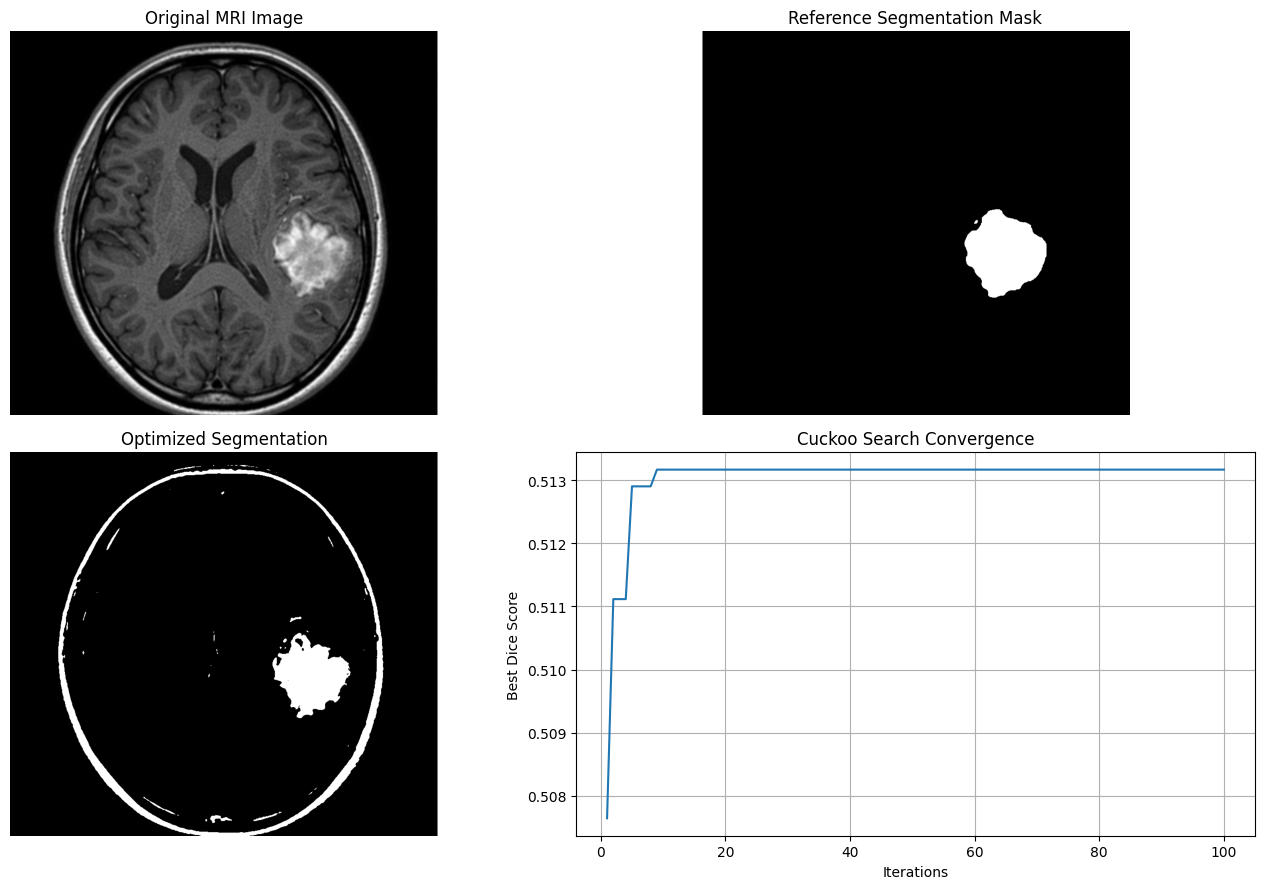


Optimized segmentation saved successfully!


In [3]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
import math

# ==========================================
# 1. LOAD INPUT IMAGES
# ==========================================

image = cv2.imread("mri_image.png", cv2.IMREAD_GRAYSCALE)
reference = cv2.imread("reference_mask.png", cv2.IMREAD_GRAYSCALE)

if image is None or reference is None:
    raise FileNotFoundError("Please upload both MRI and reference images")

if image.shape != reference.shape:
    raise ValueError("Image dimensions do not match")

reference = (reference > 127).astype(np.uint8)

print("MRI Image Loaded:", image.shape)
print("Reference Mask Loaded:", reference.shape)


# ==========================================
# 2. CUCKOO SEARCH PARAMETERS
# ==========================================

n = 15
iterations = 100
pa = 0.25
alpha = 0.5

random.seed(42)
np.random.seed(42)


# ==========================================
# 3. FITNESS FUNCTION - DICE SCORE
# ==========================================

def fitness(threshold):

    segmented = (image > threshold).astype(np.uint8)

    intersection = np.sum(segmented * reference)

    total = np.sum(segmented) + np.sum(reference)

    if total == 0:
        return 1.0

    dice = (2.0 * intersection) / total

    return dice


# ==========================================
# 4. LEVY FLIGHT
# ==========================================

def levy_flight():

    beta = 1.5

    sigma = (
        math.gamma(1 + beta) *
        math.sin(math.pi * beta / 2) /
        (
            math.gamma((1 + beta) / 2) *
            beta *
            2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = random.gauss(0, sigma)
    v = random.gauss(0, 1)

    return u / (abs(v) ** (1 / beta) + 1e-10)


# ==========================================
# 5. INITIALIZE NESTS
# ==========================================

nests = np.random.uniform(0, 255, n)

scores = np.array([fitness(x) for x in nests])

best_index = np.argmax(scores)

best_nest = nests[best_index]
best_score = scores[best_index]

history = []


# ==========================================
# 6. CUCKOO SEARCH OPTIMIZATION
# ==========================================

for iteration in range(iterations):

    # Generate new solutions
    for i in range(n):

        j = random.randrange(n)

        step = levy_flight()

        new_nest = (
            nests[i] +
            alpha * step * (nests[i] - nests[j])
        )

        new_nest = np.clip(new_nest, 0, 255)

        new_score = fitness(new_nest)

        # Replace if better
        if new_score > scores[i]:

            nests[i] = new_nest
            scores[i] = new_score

    # Update best solution
    best_index = np.argmax(scores)

    if scores[best_index] > best_score:

        best_score = scores[best_index]
        best_nest = nests[best_index]

    # Abandon worst nests
    abandon_count = max(1, int(pa * n))

    worst_indices = np.argsort(scores)[:abandon_count]

    for i in worst_indices:

        nests[i] = random.uniform(0, 255)
        scores[i] = fitness(nests[i])

    # Update global best again
    best_index = np.argmax(scores)

    if scores[best_index] > best_score:

        best_score = scores[best_index]
        best_nest = nests[best_index]

    history.append(best_score)

    print(
        f"Iteration {iteration + 1}: "
        f"Best Dice Score = {best_score:.4f}, "
        f"Threshold = {best_nest:.2f}"
    )


# ==========================================
# 7. FINAL SEGMENTATION
# ==========================================

optimal_threshold = int(round(best_nest))

segmented_image = (
    image > optimal_threshold
).astype(np.uint8) * 255

print("\n========== FINAL RESULT ==========")

print("Optimal Threshold:", optimal_threshold)
print("Best Dice Score:", round(best_score, 4))


# ==========================================
# 8. DISPLAY RESULTS
# ==========================================

plt.figure(figsize=(14, 9))

plt.subplot(2, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original MRI Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(reference, cmap="gray")
plt.title("Reference Segmentation Mask")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(segmented_image, cmap="gray")
plt.title("Optimized Segmentation")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.plot(range(1, iterations + 1), history)
plt.title("Cuckoo Search Convergence")
plt.xlabel("Iterations")
plt.ylabel("Best Dice Score")
plt.grid(True)

plt.tight_layout()
plt.show()


# ==========================================
# 9. SAVE OUTPUT IMAGE
# ==========================================

cv2.imwrite("optimized_segmentation.png", segmented_image)

print("\nOptimized segmentation saved successfully!")
